In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Jaren waarvoor we ongevallen verwerken.
# Ongevallen kunnen voor alle jaren; het verkeer van 2018-2023 komt uit de INWEVA historie,
# dat van 2024 en 2025 uit de aparte CSV-bestanden (zie de cel 'verkeer per baanvak per jaar').
JAREN = range(2018, 2026)

# Opbouw van dit notebook:
#   1. maak_baanvakken()            -> één keer: de snelwegbaanvakken uit INWEVA (netwerk van 2023)
#   2. verwerk_jaar(jaar, baanvakken) -> per jaar: ongevallen inlezen, filteren en koppelen aan een baanvak
#   3. alle jaren onder elkaar zetten in één tabel

In [2]:
#1. baanvakken maken (één keer)
# INWEVA gebruikt het wegennet van 2023. Daarom gebruiken we hier altijd wegvakken.txt van 2023,
# ook als we later ongevallen van andere jaren koppelen.

def maak_baanvakken():
    # INWEVA historie: één rij per baanvak (stuk rijbaan in één richting) met het verkeer per dag van 2018-2023
    jaarkolommen = [f"etmaal_AL_weekdag_{j}" for j in range(2018, 2024)]
    inweva = pd.read_excel("data/INWEVA/INWEVA_2023/A. Outputbestanden Excel/INWEVA_2023_historie.xlsx",
                           usecols=["VIAS_baannr", "Baantype_van", "Wegnr_van", "Ri_van", "Hm_van", "Hm_naar",
                                    "Lengte_baan_meter", "NwbId", "Traject_van", "Traject_naar"] + jaarkolommen)

    inweva_hr = inweva[inweva["Baantype_van"] == "HR"].copy()  # alleen hoofdrijbanen (geen op-/afritten)

    # wegennet 2023: welke wegvakken zijn een hoofdrijbaan van een snelweg?
    wegvakken = pd.read_csv("data/BRON/01-01-2023_31-12-2023/Netwerkgegevens/wegvakken.txt",
                            encoding="latin-1", dtype=str, usecols=["WVK_ID", "WEGBEHSRT", "BST_CODE", "ROUTELTR"])
    snelweg = wegvakken[
        (wegvakken["WEGBEHSRT"] == "R")      # Rijkswaterstaat
        & (wegvakken["BST_CODE"] == "HR")    # hoofdrijbaan
        & (wegvakken["ROUTELTR"] == "A")     # snelweg
    ]

    #alleen snelwegen filteren
    # INWEVA bevat ook N-wegen, maar heeft geen kolom "A of N".
    # Elk baanvak heeft wel een lijst NWB-wegvakken (NwbId). Staat een daarvan in 'snelweg', dan is het een snelweg.
    snelweg_ids = set(snelweg["WVK_ID"])   # set: Python kan hierin heel snel opzoeken

    def is_snelweg(nwb_ids):
        # "600461021H,508588042H" -> ["600461021", "508588042"]  (lijst maken, spaties en H/T eraf)
        ids = [x.strip().rstrip("HT") for x in nwb_ids.split(",")]
        return any(i in snelweg_ids for i in ids)   # True als minstens één wegvak een snelweg is

    baanvakken = inweva_hr[inweva_hr["NwbId"].apply(is_snelweg)].copy()

    #begin en eind van elk baanvak op volgorde zetten
    # Op de linkerbaan (L) lopen de kilometers af (Hm_van > Hm_naar). between() werkt alleen met (laag, hoog).
    baanvakken["hm_laag"] = baanvakken[["Hm_van", "Hm_naar"]].min(axis=1)
    baanvakken["hm_hoog"] = baanvakken[["Hm_van", "Hm_naar"]].max(axis=1)

    #baanvakken over een kilometersprong eruit
    # Bij een sprong (bijv. A10-ring begint weer bij km 0) is het bereik veel groter dan het baanvak echt lang is,
    # waardoor het ongevallen van elders zou "vangen".
    sprong = (baanvakken["hm_hoog"] - baanvakken["hm_laag"]) > baanvakken["Lengte_baan_meter"] + 1000
    baanvakken = baanvakken[~sprong].copy()   # ~ = niet: houd alles wat geen sprong is

    print(f"{len(baanvakken)} snelwegbaanvakken ({sprong.sum()} over een kilometersprong weggelaten)")
    return baanvakken

In [3]:
baanvakken = maak_baanvakken()   # verwacht: 3209 snelwegbaanvakken (46 weggelaten)
baanvakken

3209 snelwegbaanvakken (46 over een kilometersprong weggelaten)


,VIAS_baannr,Wegnr_van,Ri_van,Hm_van,Baantype_van,Traject_van,Hm_naar,Traject_naar,Lengte_baan_meter,NwbId,etmaal_AL_weekdag_2023,etmaal_AL_weekdag_2022,etmaal_AL_weekdag_2021,etmaal_AL_weekdag_2020,etmaal_AL_weekdag_2019,etmaal_AL_weekdag_2018,hm_laag,hm_hoog
52,174,58.0,L,171370.0,HR,Havendorpweg,170801.0,Ritthem,571,"600401624T,600401625T",16600,16600,15900,15500,18100,17300,170801.0,171370.0
53,175,58.0,R,170826.0,HR,Ritthem,171370.0,Bermweg,544,600094004H,16700,16800,16100,15800,18300,17600,170826.0,171370.0
57,209,58.0,R,170046.0,HR,Ritthem,170826.0,Ritthem,788,600093533H,13800,13900,13200,12800,14600,14300,170046.0,170826.0
58,210,58.0,L,170801.0,HR,Ritthem,169984.0,Ritthem,831,62174078T,14000,14100,13300,12800,14600,14300,169984.0,170801.0
75,291,58.0,L,169984.0,HR,Ritthem,168071.0,Middelburg-Centrum,1898,63175041T,16100,16200,15300,14700,17000,16400,168071.0,169984.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8971,153151,7.0,R,193860.0,HR,Hoogkerk,194358.0,Lijndiensten Bus,569,461559010H,28500,27400,26300,25500,30400,32000,193860.0,194358.0
8996,163234,28.0,L,199801.0,HR,Kp Julianaplein,199604.0,A7 Toekomst,203,600973611T,17100,12100,18500,21100,25200,23500,199604.0,199801.0
9017,163483,20.0,L,19090.0,HR,A20,18212.0,Rijksweg Nr,885,"600991075T,600992375T",30200,26700,28900,28000,30700,30300,18212.0,19090.0
9022,163501,20.0,L,19261.0,HR,A20,19090.0,A20,175,600992372T,29300,27600,27500,26800,30700,30300,19090.0,19261.0


In [4]:
#2. één jaar ongevallen verwerken
# Alles gebruikt de bestanden van hetzelfde jaar (ongevallen, wegvakken, hectopunten),
# zodat de wegvak-ID's altijd bij elkaar passen.

def verwerk_jaar(jaar, baanvakken):
    map_bron = f"data/BRON/01-01-{jaar}_31-12-{jaar}"

    #data inlezen (alleen de kolommen die we nodig hebben)
    # ongevallen: nummer, wegvak, ernst (AP3_CODE), licht (LGD_ID), limiet (MAXSNELHD), type ongeval (AOL_ID)
    ongevallen = pd.read_csv(f"{map_bron}/Ongevallengegevens/ongevallen.txt", encoding="latin-1", dtype=str,
                             usecols=["VKL_NUMMER", "WVK_ID", "AP3_CODE", "LGD_ID", "MAXSNELHD", "AOL_ID"])
    # wegvakken: ID, beheerder, baansoort, routeletter (A/N), wegnummer, richting (R/L)
    wegvakken = pd.read_csv(f"{map_bron}/Netwerkgegevens/wegvakken.txt", encoding="latin-1", dtype=str,
                            usecols=["WVK_ID", "WEGBEHSRT", "BST_CODE", "ROUTELTR", "WEGNUMMER", "RPE_CODE"])

    #relevante rijen selecteren: alleen hoofdrijbanen van snelwegen
    snelweg = wegvakken[
        (wegvakken["WEGBEHSRT"] == "R")      # Rijkswaterstaat
        & (wegvakken["BST_CODE"] == "HR")    # hoofdrijbaan
        & (wegvakken["ROUTELTR"] == "A")     # snelweg
    ]
    snelweg = snelweg.drop(columns=["WEGBEHSRT", "BST_CODE", "ROUTELTR"])  # nu overal hetzelfde

    #ongevallen op de snelwegen
    # merge op WVK_ID plakt weg en richting aan elk ongeval; how="inner" houdt alleen snelwegongevallen
    ongevallen_snelweg = ongevallen.merge(snelweg, on="WVK_ID", how="inner")

    #twee kolommen in zelfde vorm als inweva toevoegen
    ongevallen_snelweg["weg"] = pd.to_numeric(ongevallen_snelweg["WEGNUMMER"])   # "004" -> 4

    #positie van het ongeval = midden van zijn wegvak
    # De kolom HECTOMETER is niet altijd ingevuld (2018: 36% leeg, 2023: 4% leeg), het wegvak (WVK_ID) wel.
    # Een INWEVA-baanvak bestaat uit hele wegvakken, dus het ongeval komt toch bij het juiste baanvak uit
    # (getest: 99,3-99,9% hetzelfde baanvak als met de echte hectometer). Zo werkt het voor elk jaar hetzelfde.
    hectopunten = pd.read_csv(f"{map_bron}/Netwerkgegevens/hectopunten.txt", encoding="latin-1", dtype=str,
                              usecols=["WVK_ID", "HECTOMETER"])
    hectopunten["meter"] = pd.to_numeric(hectopunten["HECTOMETER"]) * 100   # 156 -> 15600
    midden_wegvak = hectopunten.groupby("WVK_ID")["meter"].median()        # middelste paaltje per wegvak
    ongevallen_snelweg["positie_m"] = ongevallen_snelweg["WVK_ID"].map(midden_wegvak)  # opzoeken per ongeval

    #ongevallen koppelen aan baanvakken
    # Regel: een ongeval hoort bij het baanvak op dezelfde weg, in dezelfde richting,
    # waarvan het bereik (hm_laag tot hm_hoog) de positie van het ongeval bevat.
    # 1. merge op weg + richting: elk ongeval tegen ALLE baanvakken van zijn weg en richting
    kandidaten = ongevallen_snelweg.merge(
        baanvakken[["VIAS_baannr", "Wegnr_van", "Ri_van", "hm_laag", "hm_hoog"]],
        left_on=["weg", "RPE_CODE"], right_on=["Wegnr_van", "Ri_van"])
    # 2. alleen de rij houden waar de positie binnen het baanvak valt
    raak = kandidaten[kandidaten["positie_m"].between(kandidaten["hm_laag"], kandidaten["hm_hoog"])]
    # 3. ligt een ongeval precies op de grens van twee baanvakken, dan houden we er één
    gekoppeld = raak.drop_duplicates("VKL_NUMMER").copy()

    gekoppeld["jaar"] = jaar   # zodat we na het samenvoegen weten uit welk jaar elk ongeval komt

    print(f"{jaar}: {len(ongevallen_snelweg)} snelwegongevallen, {len(gekoppeld)} gekoppeld "
          f"({len(gekoppeld) / len(ongevallen_snelweg):.1%})")
    return gekoppeld

In [5]:
#3. alle jaren verwerken en onder elkaar zetten
# [verwerk_jaar(j, baanvakken) for j in JAREN] maakt een lijst met één tabel per jaar;
# pd.concat plakt die onder elkaar tot één tabel. De kolom 'jaar' zegt uit welk jaar elk ongeval komt.
alle_ongevallen = pd.concat([verwerk_jaar(j, baanvakken) for j in JAREN], ignore_index=True)

# Resultaat: één rij per gekoppeld snelwegongeval, met het baanvak (VIAS_baannr) waar het gebeurde
alle_ongevallen

2018: 27219 snelwegongevallen, 25877 gekoppeld (95.1%)
2019: 36266 snelwegongevallen, 35008 gekoppeld (96.5%)
2020: 20663 snelwegongevallen, 20051 gekoppeld (97.0%)
2021: 21768 snelwegongevallen, 21053 gekoppeld (96.7%)
2022: 24210 snelwegongevallen, 23494 gekoppeld (97.0%)
2023: 29982 snelwegongevallen, 29115 gekoppeld (97.1%)
2024: 27887 snelwegongevallen, 27093 gekoppeld (97.2%)
2025: 27808 snelwegongevallen, 27030 gekoppeld (97.2%)


,VKL_NUMMER,AP3_CODE,AOL_ID,MAXSNELHD,LGD_ID,WVK_ID,WEGNUMMER,RPE_CODE,weg,positie_m,VIAS_baannr,Wegnr_van,Ri_van,hm_laag,hm_hoog,jaar
0,20180004322,LET,8,120,1,335159010,067,R,67.0,30700.0,9655,67.0,R,28079.0,37038.0,2018
1,20180004328,LET,8,120,1,338141017,002,L,2.0,182300.0,9766,2.0,L,181248.0,182494.0,2018
2,20180004345,LET,0,130,1,312182050,002,L,2.0,140800.0,8788,2.0,L,140390.0,141469.0,2018
3,20180004892,LET,8,120,2,205288009,020,L,20.0,44500.0,3594,20.0,L,43205.0,45971.0,2018
4,20180004909,LET,4,130,2,476560006,007,R,7.0,206300.0,15118,7.0,R,205362.0,209723.0,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208716,20250176965,UMS,8,100,3,600106146,004,R,4.0,237750.0,1617,4.0,R,236651.0,241022.0,2025
208717,20250176975,UMS,7,100,1,600280907,004,R,4.0,6500.0,4728,4.0,R,6119.0,7764.0,2025
208718,20250176987,UMS,8,100,3,225363001,004,L,4.0,5650.0,4770,4.0,L,5153.0,6128.0,2025
208719,20250176995,LET,8,100,2,414271007,012,R,12.0,148850.0,13411,12.0,R,148365.0,149300.0,2025


In [6]:
#controle: in welk baanvak zit een ongeval?
# Ongeval 20230062249 -> baanvak 11553 (A2 rechts, km 222,15-224,19, tussen A73 en Echt)
voorbeeld = alle_ongevallen[alle_ongevallen["VKL_NUMMER"] == "20230062249"]
voorbeeld[["VKL_NUMMER", "jaar", "WEGNUMMER", "RPE_CODE", "positie_m", "VIAS_baannr", "hm_laag", "hm_hoog"]]

,VKL_NUMMER,jaar,WEGNUMMER,RPE_CODE,positie_m,VIAS_baannr,hm_laag,hm_hoog
125484,20230062249,2023,002,R,223150.0,11553,222154.0,224191.0


In [7]:
# 4. Add collumn treated as a Boolean. True when speed limit changed from 120 or 130 km/h to 100 km/h, False if it remained 100 km/h, None no max speed was recorded or the speed limit was different before / after 2020. 

# AANGEPAST (Harmen): de kolom 'limiet' werd nergens in het notebook gemaakt (alleen in een losse cel die
# niet meer bestaat), waardoor deze cel bij 'Run All' een KeyError gaf. MAXSNELHD is tekst ("100") -> getal.
alle_ongevallen["limiet"] = pd.to_numeric(alle_ongevallen["MAXSNELHD"], errors="coerce")

# Median speed limit before 2020 (2018–2019)
mediaan_voor = (
    alle_ongevallen[alle_ongevallen["jaar"].isin([2018, 2019])]
    .groupby("VIAS_baannr")["limiet"]
    .median()
)

# Median speed limit after 2020 (2021–2023)
mediaan_na = (
    alle_ongevallen[alle_ongevallen["jaar"].isin([2021, 2022, 2023])]
    .groupby("VIAS_baannr")["limiet"]
    .median()
)

# Combine the medians
snelheid_df = pd.DataFrame({
    "limiet_voor_2020": mediaan_voor,
    "limiet_na_2020": mediaan_na
})

# Classify road sections
conditions = [
    snelheid_df["limiet_voor_2020"].isin([120, 130]) &
    (snelheid_df["limiet_na_2020"] == 100),

    (snelheid_df["limiet_voor_2020"] == 100) &
    (snelheid_df["limiet_na_2020"] == 100)
]

snelheid_df["treated"] = np.select(
    conditions,
    [True, False],
    default=None
)

print("True:", (snelheid_df["treated"] == True).sum())
print("False:", (snelheid_df["treated"] == False).sum())
print("NaN:", snelheid_df["treated"].isna().sum())

alle_ongevallen["treated"] = alle_ongevallen["VIAS_baannr"].map(
    snelheid_df["treated"]
)

alle_ongevallen


True: 1901
False: 759
NaN: 498


,VKL_NUMMER,AP3_CODE,AOL_ID,MAXSNELHD,LGD_ID,WVK_ID,WEGNUMMER,RPE_CODE,weg,positie_m,VIAS_baannr,Wegnr_van,Ri_van,hm_laag,hm_hoog,jaar,limiet,treated
0,20180004322,LET,8,120,1,335159010,067,R,67.0,30700.0,9655,67.0,R,28079.0,37038.0,2018,120.0,True
1,20180004328,LET,8,120,1,338141017,002,L,2.0,182300.0,9766,2.0,L,181248.0,182494.0,2018,120.0,True
2,20180004345,LET,0,130,1,312182050,002,L,2.0,140800.0,8788,2.0,L,140390.0,141469.0,2018,130.0,True
3,20180004892,LET,8,120,2,205288009,020,L,20.0,44500.0,3594,20.0,L,43205.0,45971.0,2018,120.0,True
4,20180004909,LET,4,130,2,476560006,007,R,7.0,206300.0,15118,7.0,R,205362.0,209723.0,2018,130.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208716,20250176965,UMS,8,100,3,600106146,004,R,4.0,237750.0,1617,4.0,R,236651.0,241022.0,2025,100.0,True
208717,20250176975,UMS,7,100,1,600280907,004,R,4.0,6500.0,4728,4.0,R,6119.0,7764.0,2025,100.0,False
208718,20250176987,UMS,8,100,3,225363001,004,L,4.0,5650.0,4770,4.0,L,5153.0,6128.0,2025,100.0,False
208719,20250176995,LET,8,100,2,414271007,012,R,12.0,148850.0,13411,12.0,R,148365.0,149300.0,2025,100.0,True


In [8]:
#aantal ongevallen per baanvak per jaar
# groupby op baanvak én jaar, size() telt het aantal rijen (= ongevallen) per combinatie.
# unstack zet de jaren naast elkaar, zodat je per baanvak de jaren kunt vergelijken.
per_baanvak_jaar = alle_ongevallen.groupby(["VIAS_baannr", "jaar"]).size().unstack(fill_value=0)

# voorbeeld: baanvak 3901 (A4 rechts bij Hoofddorp) -> 2018: 27, 2019: 19, 2020: 6, ... 2023: 18
per_baanvak_jaar


jaar,2018,2019,2020,2021,2022,2023,2024,2025
VIAS_baannr,,,,,,,,
174,0,4,3,3,1,5,3,4
175,6,6,4,3,2,5,4,7
209,0,1,1,4,4,2,0,2
210,1,0,2,4,0,2,2,1
291,1,1,3,2,4,2,2,2
...,...,...,...,...,...,...,...,...
144823,0,6,0,6,3,2,3,1
153151,2,5,2,2,5,3,0,0
163234,0,1,3,5,1,2,3,0


In [9]:
#verkeer per baanvak per jaar
from pathlib import Path

# 2018-2023: INWEVA historie. Daar staat de drukte in zes kolommen naast elkaar (één per jaar).
# melt zet die onder elkaar: per baanvak zes rijen, met een kolom 'jaar' en een kolom 'intensiteit'.
jaarkolommen = [f"etmaal_AL_weekdag_{j}" for j in range(2018, 2024)]
verkeer = baanvakken.melt(id_vars=["VIAS_baannr", "Lengte_baan_meter"], value_vars=jaarkolommen,
                          var_name="kolom", value_name="intensiteit")
verkeer["jaar"] = verkeer["kolom"].str[-4:].astype(int)   # "etmaal_AL_weekdag_2018" -> 2018
verkeer = verkeer.drop(columns="kolom")

# AANGEPAST (Harmen): verkeer van 2024 en 2025 toegevoegd, zodat alle grafieken 2018-2025 lopen.
# Die jaren hebben een nieuw formaat (CSV met ';', ander netwerk: 'verkeersbanen'). Elke verkeersbaan zegt in
# 'vias_baan_ids' welke van onze baanvakken (VIAS_baannr) hij dekt. Dekken meerdere verkeersbanen één baanvak,
# dan nemen we het lengte-gewogen gemiddelde. Zo krijgt ±98% van onze baanvakken een waarde voor 2024 en 2025.
def verkeer_nieuw_formaat(jaar):
    map_inweva = Path(f"data/INWEVA/INWEVA_{jaar}")

    def lees(begin):   # bestandsnamen verschillen in hoofdletters tussen 2024 en 2025
        pad = next(p for p in map_inweva.glob("*.csv") if p.name.lower().startswith(begin))
        df = pd.read_csv(pad, sep=";", dtype=str)
        df.columns = df.columns.str.lower()
        return df

    banen = lees(f"inweva_verkeersbanen_{jaar}")
    weekdag = lees(f"inweva_weekdag_{jaar}")
    vias_kolom = next(k for k in banen.columns if k.startswith("vias"))   # 2024: vias_baan_ids, 2025: vias_baan_id

    df = banen[["vbn_id", "vbn_lengte", vias_kolom]].merge(weekdag[["vbn_id", "al_e_wk"]], on="vbn_id")
    df["VIAS_baannr"] = df[vias_kolom].str.split(",")      # "3901, 3978, 4024" -> lijst
    df = df.explode("VIAS_baannr")                           # één rij per oud baanvak
    df["VIAS_baannr"] = pd.to_numeric(df["VIAS_baannr"].str.strip(), errors="coerce")
    df["intensiteit"] = pd.to_numeric(df["al_e_wk"], errors="coerce")   # gemiddeld aantal voertuigen per dag
    df["lengte"] = pd.to_numeric(df["vbn_lengte"], errors="coerce")
    df = df.dropna(subset=["VIAS_baannr", "intensiteit", "lengte"])

    df["int_x_lengte"] = df["intensiteit"] * df["lengte"]
    som = df.groupby("VIAS_baannr")[["int_x_lengte", "lengte"]].sum()
    uit = (som["int_x_lengte"] / som["lengte"]).rename("intensiteit").reset_index()
    uit["VIAS_baannr"] = uit["VIAS_baannr"].astype(int)
    uit["jaar"] = jaar
    return uit

nieuw = pd.concat([verkeer_nieuw_formaat(j) for j in (2024, 2025)], ignore_index=True)
nieuw = nieuw.merge(baanvakken[["VIAS_baannr", "Lengte_baan_meter"]], on="VIAS_baannr")   # alleen onze baanvakken
verkeer = pd.concat([verkeer, nieuw], ignore_index=True)

# AANGEPAST (Harmen): een paar baanvakken hebben intensiteit -1 (= geen waarde). Die op 0 zetten gaf
# voertuig-km = 0 terwijl hun ongevallen wél meetelden. Nu laten we die baanvak-jaren helemaal weg.
verkeer = verkeer[verkeer["intensiteit"] >= 0]
print("baanvakken met verkeer per jaar:", verkeer.groupby("jaar")["VIAS_baannr"].nunique().to_dict())

#ongevallen per baanvak per jaar (lange vorm, zodat het past bij 'verkeer')
telling = alle_ongevallen.groupby(["VIAS_baannr", "jaar"]).size().rename("ongevallen").reset_index()

#samenvoegen: verkeer links, zodat ook baanvakken zonder ongevallen meetellen (die krijgen 0)
resultaat = verkeer.merge(telling, on=["VIAS_baannr", "jaar"], how="left")
resultaat["ongevallen"] = resultaat["ongevallen"].fillna(0)

#voertuigkilometers en risico
# vkm = voertuigen per dag x 365 dagen x lengte in km; in miljoenen
resultaat["vkm_mln"] = resultaat["intensiteit"] * 365 * resultaat["Lengte_baan_meter"] / 1000 / 1_000_000
resultaat["risico"] = resultaat["ongevallen"] / resultaat["vkm_mln"] * 100   # Ongevallen per 100 miljoen vkm.

# AANGEPAST (Harmen): treated koppelen via het baanvaknummer van resultaat zelf.
# Eerst stond hier alle_ongevallen["VIAS_baannr"].map(...): pandas plakt dat op RIJNUMMER (index) aan resultaat,
# niet op baanvak. Daardoor kreeg maar ±44% van de rijen het juiste label en klopten 1.1 t/m 2.1 niet.
resultaat["treated"] = resultaat["VIAS_baannr"].map(snelheid_df["treated"])
resultaat

#resultaat[resultaat["VIAS_baannr"] == 3901]


baanvakken met verkeer per jaar: {2018: 3206, 2019: 3206, 2020: 3206, 2021: 3206, 2022: 3206, 2023: 3209, 2024: 3153, 2025: 3129}


,VIAS_baannr,Lengte_baan_meter,intensiteit,jaar,ongevallen,vkm_mln,risico,treated
0,174,571,17300.0,2018,0.0,3.605580,0.000000,True
1,175,544,17600.0,2018,6.0,3.494656,171.690719,None
2,209,788,14300.0,2018,0.0,4.112966,0.000000,False
3,210,831,14300.0,2018,1.0,4.337404,23.055263,True
4,291,1898,16400.0,2018,1.0,11.361428,8.801710,True
...,...,...,...,...,...,...,...,...
25516,144709,328,30100.0,2025,0.0,3.603572,0.000000,None
25517,144712,217,30200.0,2025,0.0,2.391991,0.000000,None
25518,163234,203,26700.0,2025,0.0,1.978336,0.000000,None
25519,163483,885,30600.0,2025,3.0,9.884565,30.350349,True


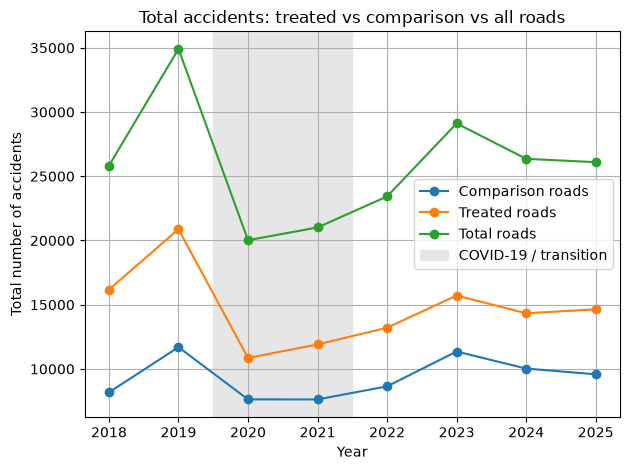

In [10]:
# 1.1
# Calculate total accidents per year for treated and comparison roads
yearly_grouped = resultaat[resultaat['treated'].isin([True, False])].groupby(
    ['jaar', 'treated']
).agg(
    total_accidents=('ongevallen', 'sum')
)

# Reshape so each treatment group becomes a separate column
accidents_by_group = yearly_grouped['total_accidents'].unstack('treated')

accidents_by_group = accidents_by_group.rename(columns={
    False: 'Comparison roads',
    True: 'Treated roads'
})

# Calculate total accidents across all road sections
yearly_total = resultaat.groupby('jaar')['ongevallen'].sum()

# Add total as a third line
accidents_by_group['Total roads'] = yearly_total

# AANGEPAST (Harmen): treated en comparison worden nu ook vóór 2020 getoond (die jaren zijn nodig om voor en na
# te vergelijken), en de COVID-19-/overgangsjaren 2020-2021 zijn grijs gemarkeerd, zoals in de deliverable.

# Plot
ax = accidents_by_group.plot(kind='line', marker='o')
ax.axvspan(2019.5, 2021.5, color='0.9', zorder=0, label='COVID-19 / transition')

ax.set_xlabel('Year')
ax.set_ylabel('Total number of accidents')
ax.set_title('Total accidents: treated vs comparison vs all roads')
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

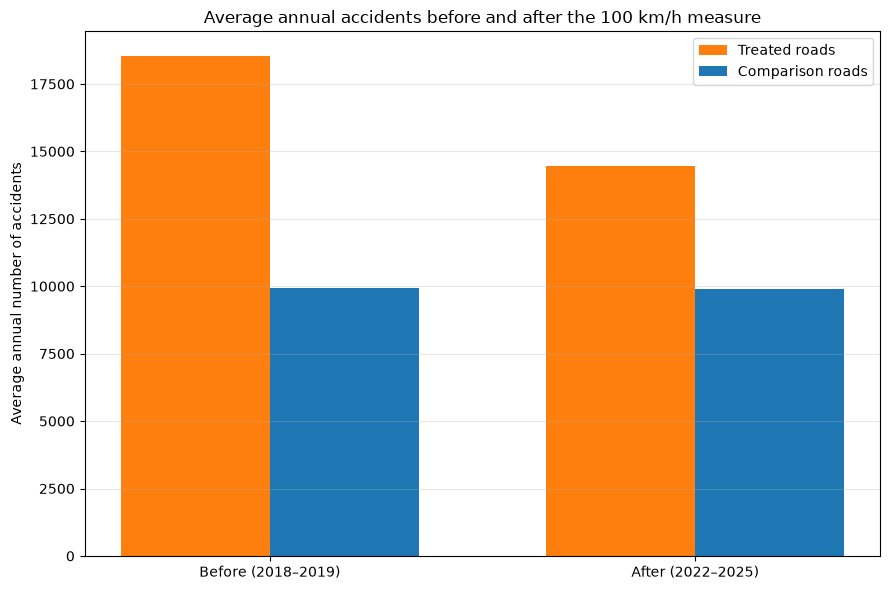

In [11]:
# 1.2
# Select the years before and after the measure
# AANGEPAST (Harmen): 'na' = 2022-2025 (was 2021-2023). 2021 is nog een COVID-jaar en hoort volgens de
# deliverables niet in de hoofdvergelijking; 2024 en 2025 zijn nu beschikbaar.
jaren_voor = [2018, 2019]
jaren_na = [2022, 2023, 2024, 2025]

# Calculate the total number of accidents per year for each group
jaarlijks = (
    resultaat[resultaat["treated"].isin([True, False])]
    .groupby(["jaar", "treated"])["ongevallen"]
    .sum()
    .unstack("treated")
    .reindex(columns=[False, True])
)

# Calculate the average annual number of accidents per group
gemiddeld_voor = jaarlijks.loc[jaren_voor].mean()
gemiddeld_na = jaarlijks.loc[jaren_na].mean()

# Create the bar chart
x = np.array([0, 1])
breedte = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    x - breedte / 2,
    [gemiddeld_voor[True], gemiddeld_na[True]],
    breedte,
    label="Treated roads",
    color='C1'

)

ax.bar(
    x + breedte / 2,
    [gemiddeld_voor[False], gemiddeld_na[False]],
    breedte,
    label="Comparison roads",
    color = 'C0'
)

ax.set_xticks(x)
ax.set_xticklabels(["Before (2018–2019)", "After (2022–2025)"])
ax.set_ylabel("Average annual number of accidents")
ax.set_title("Average annual accidents before and after the 100 km/h measure")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# 1.3
# Define periods
# AANGEPAST (Harmen): 'na' = 2022-2025 (was 2021-2023), zelfde reden als bij 1.2.
jaren_voor = [2018, 2019]
jaren_na = [2022, 2023, 2024, 2025]

# Calculate total accidents per year for treated and comparison roads
jaarlijks = (
    resultaat[resultaat["treated"].isin([True, False])]
    .groupby(["jaar", "treated"])["ongevallen"]
    .sum()
    .unstack("treated")
    .reindex(columns=[False, True])
)

# Calculate average annual accidents before and after
gemiddeld_voor = jaarlijks.loc[jaren_voor].mean()
gemiddeld_na = jaarlijks.loc[jaren_na].mean()

# Create comparison table
vergelijking = pd.DataFrame({
    "Average accidents before 2020": {
        "Treated roads": gemiddeld_voor[True],
        "Comparison roads": gemiddeld_voor[False]
    },
    "Average accidents after 2020": {
        "Treated roads": gemiddeld_na[True],
        "Comparison roads": gemiddeld_na[False]
    }
})

# Calculate absolute and percentage changes
vergelijking["Absolute change"] = (
    vergelijking["Average accidents after 2020"] - vergelijking["Average accidents before 2020"]
)

vergelijking["Percentage change (%)"] = (
    vergelijking["Absolute change"]
    / vergelijking["Average accidents before 2020"] * 100
)

print(vergelijking.round(2))

                  Average accidents before 2020  Average accidents after 2020  \
Treated roads                           18525.0                      14474.75   
Comparison roads                         9934.5                       9902.50   

                  Absolute change  Percentage change (%)  
Treated roads            -4050.25                 -21.86  
Comparison roads           -32.00                  -0.32  


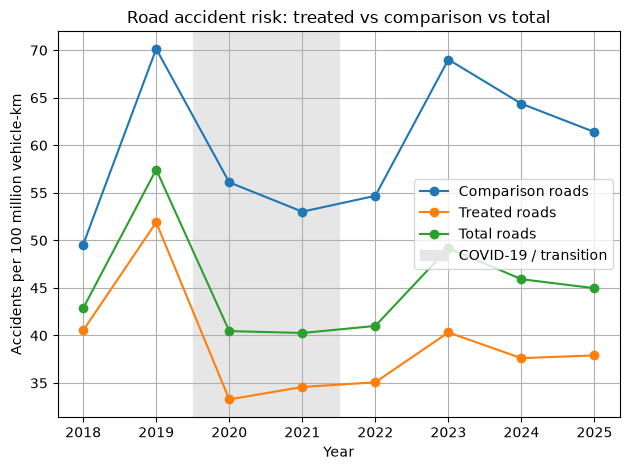

In [13]:
# 2.1
# Calculate risk per year for treated and comparison roads
yearly_grouped = resultaat[resultaat['treated'].isin([True, False])].groupby(
    ['jaar', 'treated']
).agg(
    total_accidents=('ongevallen', 'sum'),
    total_vkm_mln=('vkm_mln', 'sum')
)

yearly_grouped['overall_risk'] = (
    yearly_grouped['total_accidents'] /
    yearly_grouped['total_vkm_mln'] * 100
)

risk_by_group = yearly_grouped['overall_risk'].unstack('treated')

risk_by_group = risk_by_group.rename(columns={
    False: 'Comparison roads',
    True: 'Treated roads'
})

# Calculate total risk across all road sections
yearly_total = resultaat.groupby('jaar').agg(
    total_accidents=('ongevallen', 'sum'),
    total_vkm_mln=('vkm_mln', 'sum')
)

yearly_total['Total roads'] = (
    yearly_total['total_accidents'] /
    yearly_total['total_vkm_mln'] * 100
)

# Add total as a third line
risk_by_group['Total roads'] = yearly_total['Total roads']

# AANGEPAST (Harmen): treated en comparison ook vóór 2020 tonen, COVID-19-/overgangsjaren grijs gemarkeerd.

# Plot
ax = risk_by_group.plot(kind='line', marker='o')
ax.axvspan(2019.5, 2021.5, color='0.9', zorder=0, label='COVID-19 / transition')

ax.set_xlabel('Year')
ax.set_ylabel('Accidents per 100 million vehicle-km')
ax.set_title('Road accident risk: treated vs comparison vs total')
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

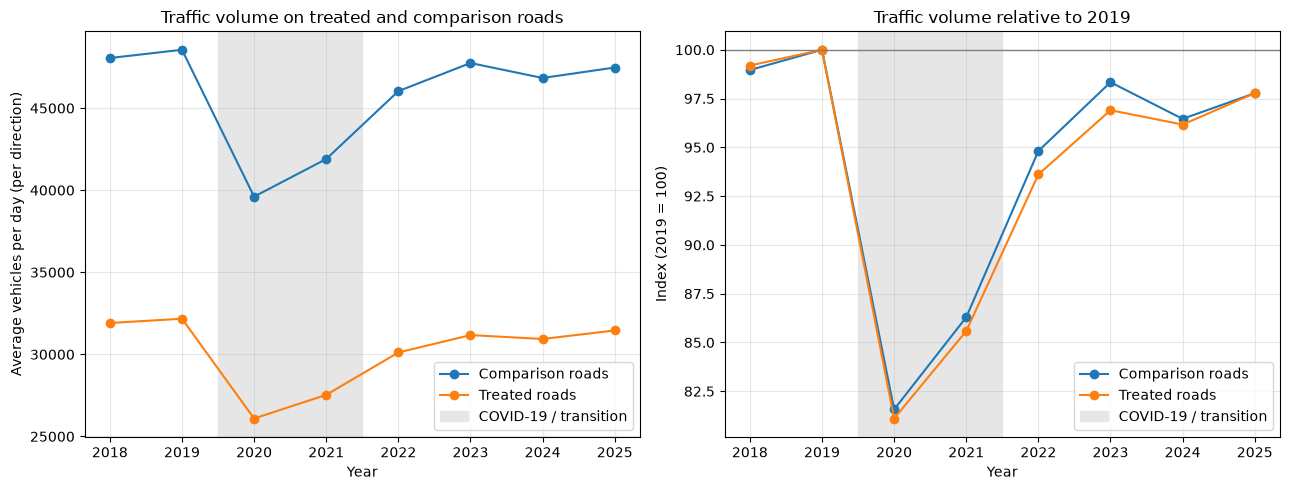

treated,Comparison roads,Treated roads
jaar,,
2018,99.0,99.2
2019,100.0,100.0
2020,81.6,81.1
2021,86.3,85.6
2022,94.8,93.6
2023,98.3,96.9
2024,96.5,96.2
2025,97.8,97.8


In [14]:
# 2.2 Traffic volume (2018-2025): verkeersintensiteit voor treated en comparison roads
# Per groep het lengte-gewogen gemiddelde aantal voertuigen per dag (= alle voertuigkilometers / totale lengte),
# zodat een lang baanvak zwaarder meetelt dan een kort. Rechts als index (2019 = 100), zodat je de
# verandering van beide groepen direct kunt vergelijken: dit laat zien waarom correctie voor de drukte nodig is.
v = resultaat[resultaat["treated"].isin([True, False])].copy()
v["int_x_lengte"] = v["intensiteit"] * v["Lengte_baan_meter"]
som = v.groupby(["jaar", "treated"])[["int_x_lengte", "Lengte_baan_meter"]].sum()
intensiteit_groep = (som["int_x_lengte"] / som["Lengte_baan_meter"]).unstack("treated")
intensiteit_groep = intensiteit_groep.rename(columns={False: "Comparison roads", True: "Treated roads"})

index_2019 = intensiteit_groep / intensiteit_groep.loc[2019] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
intensiteit_groep.plot(ax=axes[0], marker="o")
axes[0].set_ylabel("Average vehicles per day (per direction)")
axes[0].set_title("Traffic volume on treated and comparison roads")
index_2019.plot(ax=axes[1], marker="o")
axes[1].axhline(100, color="0.5", linewidth=1)
axes[1].set_ylabel("Index (2019 = 100)")
axes[1].set_title("Traffic volume relative to 2019")
for ax in axes:
    ax.axvspan(2019.5, 2021.5, color="0.9", zorder=0, label="COVID-19 / transition")
    ax.set_xlabel("Year")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

index_2019.round(1)

In [15]:
# Hulpfunctie voor 2.3 en 2.4: Poisson-regressie met vaste effecten per baanvak en per jaar
#
# Model:  log E[ongevallen] = log(voertuig-km) + effect_baanvak + effect_jaar + beta * term
#   - log(voertuig-km) als 'offset': we modelleren het RISICO (ongevallen per gereden km), niet het aantal
#   - effect per baanvak ('wegvakeffect'): vaste verschillen tussen baanvakken (bijv. drukke stadsringen) vallen weg
#   - effect per jaar: alles wat ALLE snelwegen raakte (COVID-19, registratie, weer) valt weg
#   - exp(beta) = incidence-rate ratio (IRR): de verandering van het risico op treated roads, gedeeld door die
#     op comparison roads. IRR 0.80 = op treated roads daalde het risico 20% sterker dan op comparison roads.
#
# Met ±2.600 baanvakken is een gewone regressie met een dummy per baanvak traag (±1 minuut per model).
# ConditionalPoisson (statsmodels) schat precies hetzelfde model, maar 'conditioneert' de baanvakeffecten weg,
# waardoor het in minder dan een seconde klaar is. De standaardfouten zijn cluster-robuust per baanvak:
# ongevallen op hetzelfde baanvak hangen over de jaren samen, en ongevalsaantallen variëren vaak meer dan een
# Poisson-verdeling aanneemt (overdispersie). Daarmee is Poisson + robuuste fouten hier geschikt (i.p.v. negative binomial).
# Controle: een gewone GLM met een dummy per baanvak gaf dezelfde IRR (0.794) en vrijwel hetzelfde interval.
from scipy.stats import norm
from statsmodels.discrete.conditional_models import ConditionalPoisson

def poisson_fe(data, termen):
    """Schat het model voor de kolommen in `termen`; geeft per term de IRR, het 95%-BI en de p-waarde."""
    # baanvakken waar het aantal ongevallen in deze selectie van jaren nooit verandert (bijv. elk jaar 0)
    # zeggen niets over een verandering; ConditionalPoisson laat ze ook weg. Wij doen dat vooraf.
    data = data[data.groupby("VIAS_baannr")["ongevallen"].transform("nunique") > 1]
    jaar_dummies = pd.get_dummies(data["jaar"], prefix="jaar", drop_first=True, dtype=float)
    X = pd.concat([data[termen].astype(float), jaar_dummies], axis=1).to_numpy()
    y = data["ongevallen"].to_numpy(float)
    offset = np.log(data["vkm_mln"].to_numpy(float))
    baanvak = data["VIAS_baannr"].to_numpy()

    fit = ConditionalPoisson(y, X, groups=baanvak, offset=offset).fit(method="bfgs", maxiter=1000)
    b = fit.params

    # cluster-robuuste standaardfouten per baanvak (sandwich-formule)
    eta = X @ b + offset
    e = np.exp(eta - pd.Series(eta).groupby(baanvak).transform("max").to_numpy())
    p = e / pd.Series(e).groupby(baanvak).transform("sum").to_numpy()   # verwacht aandeel van elk jaar binnen een baanvak
    n = pd.Series(y).groupby(baanvak).transform("sum").to_numpy()        # totaal aantal ongevallen per baanvak
    x_c = X - pd.DataFrame(X * p[:, None]).groupby(baanvak).transform("sum").to_numpy()
    scores = pd.DataFrame(x_c * (y - n * p)[:, None]).groupby(baanvak).sum().to_numpy()
    H = -(x_c * (n * p)[:, None]).T @ x_c
    G = len(np.unique(baanvak))
    H_inv = np.linalg.inv(H)
    se = np.sqrt(np.diag(H_inv @ (scores.T @ scores) @ H_inv * G / (G - 1)))

    k = len(termen)
    return pd.DataFrame({
        "term": termen,
        "IRR": np.exp(b[:k]),
        "CI_low": np.exp(b[:k] - 1.96 * se[:k]),
        "CI_high": np.exp(b[:k] + 1.96 * se[:k]),
        "p_value": 2 * norm.sf(np.abs(b[:k] / se[:k])),
    })

# modeldata: alleen treated en comparison baanvakken met verkeer (vkm > 0),
# zonder baanvakken die in geen enkel jaar een ongeval hadden (die zeggen niets over een verandering)
model_data = resultaat[resultaat["treated"].isin([True, False]) & (resultaat["vkm_mln"] > 0)].copy()
model_data = model_data[model_data.groupby("VIAS_baannr")["ongevallen"].transform("sum") > 0]
model_data["behandeld"] = (model_data["treated"] == True).astype(int)
print(f"modeldata: {model_data['VIAS_baannr'].nunique()} baanvakken, {len(model_data)} baanvak-jaren")

modeldata: 2660 baanvakken, 21146 baanvak-jaren


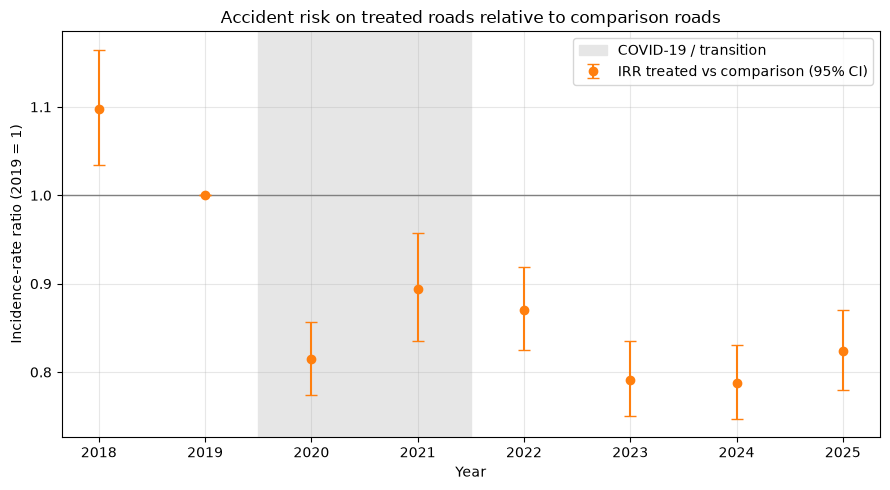

,jaar,IRR,CI_low,CI_high,p_value
0,2018,1.097,1.034,1.165,0.002
1,2019,1.000,1.000,1.000,NaN
2,2020,0.815,0.774,0.857,0.000
3,2021,0.894,0.835,0.958,0.001
4,2022,0.871,0.825,0.919,0.000
5,2023,0.791,0.750,0.835,0.000
6,2024,0.788,0.747,0.830,0.000
7,2025,0.824,0.780,0.870,0.000


In [16]:
# 2.3 Event study (2018-2025): verschil tussen treated en comparison roads per jaar, met 2019 als referentie
# Voor elk jaar behalve 2019 een term 'behandeld x jaar'. De IRR van een jaar is:
#     (risico treated / risico comparison in dat jaar)  /  (dezelfde verhouding in 2019)
#   - vóór de maatregel (2018) hoort de IRR rond 1 te liggen: dan ontwikkelden beide groepen zich gelijk
#     (dat is de belangrijkste aanname van difference-in-differences)
#   - na de maatregel laat de IRR zien hoeveel het risico op treated roads extra veranderde
REFERENTIEJAAR = 2019
jaren = sorted(j for j in model_data["jaar"].unique() if j != REFERENTIEJAAR)
for j in jaren:
    model_data[f"behandeld_{j}"] = model_data["behandeld"] * (model_data["jaar"] == j)

event_study = poisson_fe(model_data, [f"behandeld_{j}" for j in jaren])
event_study["jaar"] = jaren
referentie = pd.DataFrame({"term": ["referentie"], "IRR": [1.0], "CI_low": [1.0], "CI_high": [1.0],
                           "p_value": [np.nan], "jaar": [REFERENTIEJAAR]})
event_study = pd.concat([event_study, referentie]).sort_values("jaar").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1, color="0.5", linewidth=1)
ax.errorbar(event_study["jaar"], event_study["IRR"],
            yerr=[event_study["IRR"] - event_study["CI_low"], event_study["CI_high"] - event_study["IRR"]],
            fmt="o", capsize=4, color="C1", label="IRR treated vs comparison (95% CI)")
ax.axvspan(2019.5, 2021.5, color="0.9", zorder=0, label="COVID-19 / transition")
ax.set_xlabel("Year")
ax.set_ylabel("Incidence-rate ratio (2019 = 1)")
ax.set_title("Accident risk on treated roads relative to comparison roads")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

event_study[["jaar", "IRR", "CI_low", "CI_high", "p_value"]].round(3)

In [17]:
# 2.4 Difference-in-Differences (DiD): één getal voor de relatieve verandering in het ongevalsrisico
# vóór = 2018-2019, na = 2022-2025; de COVID-19-/overgangsjaren 2020-2021 laten we weg.
# behandeld_na = 1 voor treated roads in de jaren na de maatregel, anders 0.
# Model: Poisson met voertuig-km als blootstelling, baanvak- en jaareffecten (zie de hulpfunctie hierboven).
def did(data, voor, na):
    d = data[data["jaar"].isin(voor + na)].copy()
    d["behandeld_na"] = d["behandeld"] * d["jaar"].isin(na)
    return poisson_fe(d, ["behandeld_na"]).iloc[0]

VOOR = [2018, 2019]
NA = [2022, 2023, 2024, 2025]
did_resultaten = {"Main: before 2018-2019, after 2022-2025": did(model_data, VOOR, NA)}

# Gevoeligheidsanalyse 1: van 2018 naar 2019 steeg het aantal GEREGISTREERDE ongevallen sterk terwijl het verkeer
# nauwelijks veranderde (registratie). Daarom ook met alleen 2019 als 'vóór'.
did_resultaten["Before = 2019 only"] = did(model_data, [2019], NA)

# Gevoeligheidsanalyse 2: strengere comparison-groep. Een mediaan van 100 laat toe dat bijna de helft van de
# ongevallen vóór 2020 een limiet van 120/130 had. Hier alleen comparison roads met géén enkele 120/130,
# minstens 80% 100 km/u en minstens 5 ongevallen met een limiet in 2018-2019.
voor_2020 = alle_ongevallen[alle_ongevallen["jaar"].isin([2018, 2019])].dropna(subset=["limiet"])
per_baanvak = voor_2020.groupby("VIAS_baannr")["limiet"].agg(
    n="size", hoog=lambda s: s.isin([120, 130]).mean(), honderd=lambda s: (s == 100).mean())
strenge_comparison = per_baanvak[(per_baanvak["hoog"] == 0) & (per_baanvak["honderd"] >= 0.8)
                                 & (per_baanvak["n"] >= 5)].index
streng = model_data[(model_data["behandeld"] == 1) | model_data["VIAS_baannr"].isin(strenge_comparison)]
did_resultaten["Stricter comparison group"] = did(streng, VOOR, NA)

# tabel: IRR, 95%-betrouwbaarheidsinterval, p-waarde en de verandering in procenten
did_tabel = pd.DataFrame(did_resultaten).T
did_tabel = pd.DataFrame({
    "IRR": did_tabel["IRR"].astype(float).round(3),
    "95% CI": [f"{lo:.3f} – {hi:.3f}" for lo, hi in zip(did_tabel["CI_low"], did_tabel["CI_high"])],
    "p-value": did_tabel["p_value"].astype(float).map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"),
    "Change in risk vs comparison": (did_tabel["IRR"].astype(float) - 1).map("{:+.1%}".format),
})
print(f"comparison roads: {model_data.loc[model_data['behandeld'] == 0, 'VIAS_baannr'].nunique()} (main), "
      f"{streng.loc[streng['behandeld'] == 0, 'VIAS_baannr'].nunique()} (stricter)")
did_tabel

comparison roads: 759 (main), 357 (stricter)


,IRR,95% CI,p-value,Change in risk vs comparison
"Main: before 2018-2019, after 2022-2025",0.783,0.753 – 0.815,<0.001,-21.7%
Before = 2019 only,0.815,0.778 – 0.853,<0.001,-18.5%
Stricter comparison group,0.767,0.730 – 0.805,<0.001,-23.3%
